# 1D-CNN and Transformer

**Owner:** Abhishek Kumar Patel. Phase 2, deep learning (notebook 04 of 07).

## Purpose

Build the two non-recurrent sequence models of the project, a 1D convolutional network (CNN) and a Transformer encoder, and compare them fairly with the LSTM and GRU of notebook 03. Both read the last 30 cycles of the 14 useful sensors and predict Remaining Useful Life (RUL). The questions are: which design choices of each architecture matter, does either beat the recurrent models and the Phase 1 Random Forest, and does either fix the Phase 1 weakness (underprediction of engines with a true RUL above 200 cycles)?

## Method

**Data and protocol (identical to notebook 03).** Windows come from `src/sequences.py` (window 30, scaler fitted on the 80 training engines only, no look-ahead). Training uses all windows of the 80 training engines. The 20 validation engines supply (a) all their windows, used for early stopping and for choosing a configuration, and (b) the 100 fixed validation points, used only to report. The test set is never scored here: the notebook only writes test predictions to a file. Targets are the true, uncapped RUL divided by 100.

**Training.** AdamW (learning rate 1e-3 unless a sweep changes it), MSE loss, batch size 256, gradient clipping at 1.0, at most 60 epochs, early stopping with patience 8 on validation-window MAE and the best weights restored (`train.fit`, unchanged). All runs use CPU, which is deterministic for this model size, and independent runs are spread over 6 worker processes with one thread each (`src/cnn_experiments.py`).

**Experiment design.** For each model there is a baseline, and every factor is changed alone with all others fixed (seed 42).

| Model | Baseline (bold values below) | Factors changed one at a time |
| --- | --- | --- |
| CNN | 2 conv layers, 64 channels, kernel 5, dilation 1, no normalisation, no residual, average pooling, dropout 0.2, weight decay 1e-4 | normalisation (batch, layer), residual connections, pooling (max, last step), dilation (1, 2, 4 per layer), layers (3, 4), kernel (3, 7), dropout (0, 0.1, 0.3, 0.5), weight decay (0, 1e-3) |
| Transformer | `d_model` 32, 4 heads, 2 layers, feed-forward size 64 (2x), sinusoidal positions, mean pooling, dropout 0.1, weight decay 1e-4, learning rate 1e-3 | positional encoding (learned), pooling (last step), `d_model` (64), layers (1, 3), heads (2), dropout (0, 0.2, 0.3), weight decay (0, 1e-3), learning rate (3e-4, 3e-3) |

A larger Transformer (`d_model` 128, 8 heads, 4 layers, feed-forward 4x) is trained as a diagnostic for overfitting. It is not in the selection pool.

**Selection rule (written before any result is looked at; same as notebook 03).**

1. The score used to choose a configuration is the MAE in cycles over *all windows of the 20 validation engines*, taken at the epoch whose weights are kept (`val_window_mae`). It is not the 100-point score, because 100 points are too few and too noisy to choose from and selecting on them would contaminate the number reported for them.
2. For each model the pool is the baseline, the one-factor runs and one combined run. The combined run uses, for every factor group, the value that improved `val_window_mae` over the baseline by more than 0.5 cycles (about the seed-to-seed spread of one configuration in notebook 03) and keeps the baseline value for the other groups. Factor groups are: normalisation, residual, pooling, dilation, layers, kernel, dropout, weight decay (CNN); positional encoding, pooling, `d_model`, layers, heads, dropout, weight decay, learning rate (Transformer).
3. The chosen configuration is the pool member with the lowest `val_window_mae`. Differences below 0.05 cycles are ties and the smaller model (fewer parameters) wins.
4. The chosen CNN and Transformer are then trained with seeds 42, 43 and 44. The model saved as `cnn1d_v1` or `transformer_v1` and used for the prediction files is the seed 42 run. The 100-point numbers are reported once for each chosen configuration, as mean and standard deviation (`ddof=1`) over the three seeds.
5. No other search is run on the 100 points and no test metric is computed.

**Run time.** The whole notebook ran in about 21 minutes wall-clock on an 8-core laptop (6 worker processes), which is above the 15-minute target. The grids were not reduced because the one-factor design needs every run (33 sweep runs including the large diagnostic, 2 combined runs, 6 seed runs, plus timing). To shorten a re-run, run the CNN and the Transformer sweeps in separate sessions or lower `epochs` in `cx.DEFAULTS`; the stored results were produced with the settings shown here.

## Results

### Setup

Imports, paths and plotting defaults. `ROOT` is found from the working directory, so the notebook must run from `notebooks/phase2/`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # run from notebooks/phase2
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import Ridge

import cnn_experiments as cx
import rnn_experiments as rx
import train
from dl_models import CNN1DRegressor, TransformerRegressor, build_model
from evaluation import split_train_val, validation_points
from load_data import load_train
from sequences import DEFAULT_WINDOW

RESULTS = ROOT / "results" / "phase2"
FIG_DIR = RESULTS / "figures"
MODEL_DIR = RESULTS / "models"
for folder in (FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

WORKERS = 6
SEEDS = (42, 43, 44)
TIE = 0.05      # cycles; differences below this are ties (smaller model wins)
MIN_GAIN = 0.5  # cycles; a factor value enters the combined run only if it gains more than this
COLORS = {"cnn1d": "#2ca02c", "transformer": "#9467bd", "lstm": "#d62728", "gru": "#1f77b4"}
plt.rcParams.update({"savefig.dpi": 150, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(1)


def save_fig(fig, name):
    # Save a figure under results/phase2/figures and show it.
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()

### Data

Build the windows once (this reuses Prateek's pipeline through `rnn_experiments.get_data`) and print the shapes. The scaler is fitted on the 80 training engines only.

In [2]:
data = rx.get_data(DEFAULT_WINDOW)
train_df, val_df = split_train_val(load_train())
points = validation_points(val_df)
print("training engines:", train_df["engine_id"].nunique(), "| windows:", data["X_tr"].shape)
print("validation engines:", val_df["engine_id"].nunique(), "| windows:", data["X_va"].shape)
print("100 validation points:", data["X_pt"].shape, "| test points:", data["X_te"].shape)

training engines: 80 | windows: (16390, 30, 14)
validation engines: 20 | windows: (4241, 30, 14)
100 validation points: (100, 30, 14) | test points: (100, 30, 14)


### Task A: the CNN and its receptive field

Stacking $L$ stride-1 convolutions with kernel $k$ and dilations $d_1,\dots,d_L$ gives each output position a receptive field of $1+\sum_{l}d_l\,(k-1)$ cycles. The starter model (two layers, $k=5$, no dilation) sees only $1+2\cdot4=9$ of the 30 cycles at any position, although global pooling then combines all positions. Deeper stacks, a larger kernel or dilation widen the field. The table lists the receptive field of every CNN variant used below.

In [3]:
variants = {
    "baseline (2 layers, k=5)": {},
    "3 layers": {"layers": 3},
    "4 layers": {"layers": 4},
    "kernel 3": {"kernel": 3},
    "kernel 7": {"kernel": 7},
    "dilation 2": {"dilation": 2},
    "dilation 4": {"dilation": 4},
    "dilation exp, 3 layers (1,2,4)": {"layers": 3, "dilation": "exp"},
}
rf = pd.DataFrame(
    [{"variant": k, "receptive_field_cycles": CNN1DRegressor(**v).receptive_field,
      "share_of_window_30": CNN1DRegressor(**v).receptive_field / DEFAULT_WINDOW}
     for k, v in variants.items()]
)
print(rf.round(2).to_string(index=False))

                       variant  receptive_field_cycles  share_of_window_30
      baseline (2 layers, k=5)                       9                0.30
                      3 layers                      13                0.43
                      4 layers                      17                0.57
                      kernel 3                       5                0.17
                      kernel 7                      13                0.43
                    dilation 2                      17                0.57
                    dilation 4                      33                1.10
dilation exp, 3 layers (1,2,4)                      29                0.97


**Padding.** The convolutions use symmetric zero padding (`padding = d*(k-1)/2`), not causal (left-only) padding. This is correct here because the causality that matters is already enforced by the window: a sample contains only cycles up to the current cycle $t$, so every position inside it is in the past, and the output at any position can only depend on cycles $\le t$. The padding only decides what a filter sees beyond the two ends of the window (zeros, which equal the training mean after standardisation), and the head pools over the whole window.

### Task A and C: CNN sweep (one factor at a time)

Train the CNN baseline and every one-factor variant of the plan above in parallel (seed 42). Each result is the validation-window MAE at the kept epoch.

In [4]:
CNN_BASE = dict(channels=64, kernel=5, dropout=0.2, layers=2, dilation=1, norm="none", residual=False, pool="avg")
CNN_TRAIN_BASE = dict(weight_decay=1e-4)

# (factor group, value, model kwargs override, training override)
CNN_FACTORS = (
    [("norm", v, {"norm": v}, {}) for v in ("batch", "layer")]
    + [("residual", True, {"residual": True}, {})]
    + [("pool", v, {"pool": v}, {}) for v in ("max", "last")]
    + [("dilation", v, {"dilation": v}, {}) for v in (2, 4)]
    + [("layers", v, {"layers": v}, {}) for v in (3, 4)]
    + [("kernel", v, {"kernel": v}, {}) for v in (3, 7)]
    + [("dropout", v, {"dropout": v}, {}) for v in (0, 0.1, 0.3, 0.5)]
    + [("weight_decay", v, {}, {"weight_decay": v}) for v in (0, 1e-3)]
)


def cnn_config(kw_override, train_override, **extra):
    return {"model": "cnn1d", "kw": {**CNN_BASE, **kw_override}, **CNN_TRAIN_BASE, **train_override, **extra}


cnn_configs = [cnn_config({}, {})] + [cnn_config(k, t) for _, _, k, t in CNN_FACTORS]
cnn_runs = cx.run_many(cnn_configs, workers=WORKERS)
print(f"{len(cnn_runs)} CNN runs finished")

18 CNN runs finished


In [5]:
def sweep_frame(model, factors, runs):
    # One row per run: baseline first, then the factor runs in order.
    rows = [{"model": model, "factor": "baseline", "value": "baseline"}] + [
        {"model": model, "factor": f, "value": v} for f, v, _, _ in factors
    ]
    for row, r in zip(rows, runs):
        row.update(
            val_window_mae=r["val_window_mae"], train_loss_final=r["train_loss_final"],
            train_mae=r["train_mae"], best_epoch=r["best_epoch"], epochs_run=r["epochs_run"],
            n_params=r["n_params"],
        )
    df = pd.DataFrame(rows)
    df["delta_vs_baseline"] = df["val_window_mae"] - df.loc[0, "val_window_mae"]
    return df


cnn_df = sweep_frame("cnn1d", CNN_FACTORS, cnn_runs)
print(cnn_df.drop(columns="model").round(3).to_string(index=False))

      factor    value  val_window_mae  train_loss_final  train_mae  best_epoch  epochs_run  n_params  delta_vs_baseline
    baseline baseline          31.364             0.110     22.036           7          15     25153              0.000
        norm    batch          32.705             0.129     23.052           2          10     25409              1.341
        norm    layer          29.715             0.019      6.606          33          41     25409             -1.649
    residual     True          31.202             0.092     20.542           8          16     25153             -0.162
        pool      max          34.286             0.032      8.367           9          17     25153              2.922
        pool     last          30.626             0.149     26.987          14          22     25153             -0.738
    dilation        2          29.772             0.084     19.841           9          17     25153             -1.592
    dilation        4          28.861   

The combined CNN run follows selection-rule step 2: for each factor group, take the value with the largest gain over the baseline, but only if that gain exceeds 0.5 cycles.

In [6]:
def combined_overrides(df, factors):
    # Best value per factor group if it beats the baseline by more than MIN_GAIN.
    kw, tr, used = {}, {}, []
    sweep = df[df["factor"] != "baseline"]
    for group in dict.fromkeys(f for f, _, _, _ in factors):
        g = sweep[sweep["factor"] == group]
        best = g.loc[g["val_window_mae"].idxmin()]
        if -best["delta_vs_baseline"] > MIN_GAIN:
            value = best["value"]
            for f, v, k, t in factors:
                if f == group and v == value:
                    kw.update(k); tr.update(t)
            used.append((group, value, round(float(best["delta_vs_baseline"]), 2)))
    return kw, tr, used


cnn_kw, cnn_tr, cnn_used = combined_overrides(cnn_df, CNN_FACTORS)
print("combined CNN uses:", cnn_used if cnn_used else "nothing (no factor beat the baseline by more than 0.5)")
cnn_comb_run = cx.run_one(cnn_config(cnn_kw, cnn_tr))
cnn_comb = {"model": "cnn1d", "factor": "combined", "value": "combined",
            "val_window_mae": cnn_comb_run["val_window_mae"], "train_loss_final": cnn_comb_run["train_loss_final"],
            "train_mae": cnn_comb_run["train_mae"], "best_epoch": cnn_comb_run["best_epoch"],
            "epochs_run": cnn_comb_run["epochs_run"], "n_params": cnn_comb_run["n_params"],
            "delta_vs_baseline": cnn_comb_run["val_window_mae"] - cnn_df.loc[0, "val_window_mae"]}
cnn_df = pd.concat([cnn_df, pd.DataFrame([cnn_comb])], ignore_index=True)
print(f"combined run: val-window MAE {cnn_comb_run['val_window_mae']:.2f} (baseline {cnn_df.loc[0, 'val_window_mae']:.2f}), params {cnn_comb_run['n_params']}")

combined CNN uses: [('norm', 'layer', -1.65), ('pool', 'last', -0.74), ('dilation', 4, -2.5)]


combined run: val-window MAE 29.27 (baseline 31.36), params 25409


### Task B and C: Transformer sweep (one factor at a time)

Same design for the Transformer. The Transformer might need a smaller learning rate to train stably, so the learning rate is one of the factors. A warm-up schedule is not added: if no learning rate in the grid trains stably, that is reported instead.

In [7]:
TR_BASE = dict(d_model=32, heads=4, layers=2, dim_ff=64, dropout=0.1, pos="sinusoidal", pool="mean")
TR_TRAIN_BASE = dict(weight_decay=1e-4, lr=1e-3)

TR_FACTORS = (
    [("pos", "learned", {"pos": "learned"}, {})]
    + [("pool", "last", {"pool": "last"}, {})]
    + [("d_model", 64, {"d_model": 64, "dim_ff": 128}, {})]
    + [("layers", v, {"layers": v}, {}) for v in (1, 3)]
    + [("heads", 2, {"heads": 2}, {})]
    + [("dropout", v, {"dropout": v}, {}) for v in (0, 0.2, 0.3)]
    + [("weight_decay", v, {}, {"weight_decay": v}) for v in (0, 1e-3)]
    + [("lr", v, {}, {"lr": v}) for v in (3e-4, 3e-3)]
)
TR_LARGE = {"d_model": 128, "heads": 8, "layers": 4, "dim_ff": 512}  # diagnostic only


def tr_config(kw_override, train_override, **extra):
    return {"model": "transformer", "kw": {**TR_BASE, **kw_override}, **TR_TRAIN_BASE, **train_override, **extra}


tr_configs = [tr_config({}, {})] + [tr_config(k, t) for _, _, k, t in TR_FACTORS] + [tr_config(TR_LARGE, {})]
tr_runs = cx.run_many(tr_configs, workers=WORKERS)
tr_large_run = tr_runs.pop()  # the last config is the large-model diagnostic
print(f"{len(tr_runs)} Transformer runs finished (+1 diagnostic)")

tr_df = sweep_frame("transformer", TR_FACTORS, tr_runs)
print(tr_df.drop(columns="model").round(3).to_string(index=False))
print(f"\nlarge diagnostic (d_model 128, 8 heads, 4 layers): params {tr_large_run['n_params']}, "
      f"train MAE {tr_large_run['train_mae']:.2f}, val-window MAE {tr_large_run['val_window_mae']:.2f} "
      f"(baseline: train {tr_runs[0]['train_mae']:.2f}, val {tr_runs[0]['val_window_mae']:.2f})")

14 Transformer runs finished (+1 diagnostic)
      factor    value  val_window_mae  train_loss_final  train_mae  best_epoch  epochs_run  n_params  delta_vs_baseline
    baseline baseline          27.822             0.104     20.629           6          14     17665              0.000
         pos  learned          28.854             0.084     17.525           6          14     21761              1.032
        pool     last          27.801             0.115     21.518           5          13     17665             -0.020
     d_model       64          28.809             0.119     21.301           2          10     68097              0.987
      layers        1          27.983             0.086     20.421          13          21      9121              0.161
      layers        3          27.070             0.066     15.502          13          21     26209             -0.752
       heads        2          27.666             0.107     21.055           6          14     17665             -0

In [8]:
tr_kw, tr_tr, tr_used = combined_overrides(tr_df, TR_FACTORS)
print("combined Transformer uses:", tr_used if tr_used else "nothing (no factor beat the baseline by more than 0.5)")
tr_comb_run = cx.run_one(tr_config(tr_kw, tr_tr))
tr_comb = {"model": "transformer", "factor": "combined", "value": "combined",
           "val_window_mae": tr_comb_run["val_window_mae"], "train_loss_final": tr_comb_run["train_loss_final"],
           "train_mae": tr_comb_run["train_mae"], "best_epoch": tr_comb_run["best_epoch"],
           "epochs_run": tr_comb_run["epochs_run"], "n_params": tr_comb_run["n_params"],
           "delta_vs_baseline": tr_comb_run["val_window_mae"] - tr_df.loc[0, "val_window_mae"]}
tr_df = pd.concat([tr_df, pd.DataFrame([tr_comb])], ignore_index=True)
print(f"combined run: val-window MAE {tr_comb_run['val_window_mae']:.2f} (baseline {tr_df.loc[0, 'val_window_mae']:.2f}), params {tr_comb_run['n_params']}")

combined Transformer uses: [('layers', 3, -0.75), ('dropout', 0, -0.61)]


combined run: val-window MAE 27.62 (baseline 27.82), params 26209


Sweep figure: the change of validation-window MAE against the baseline for each factor value (bars to the left are better).

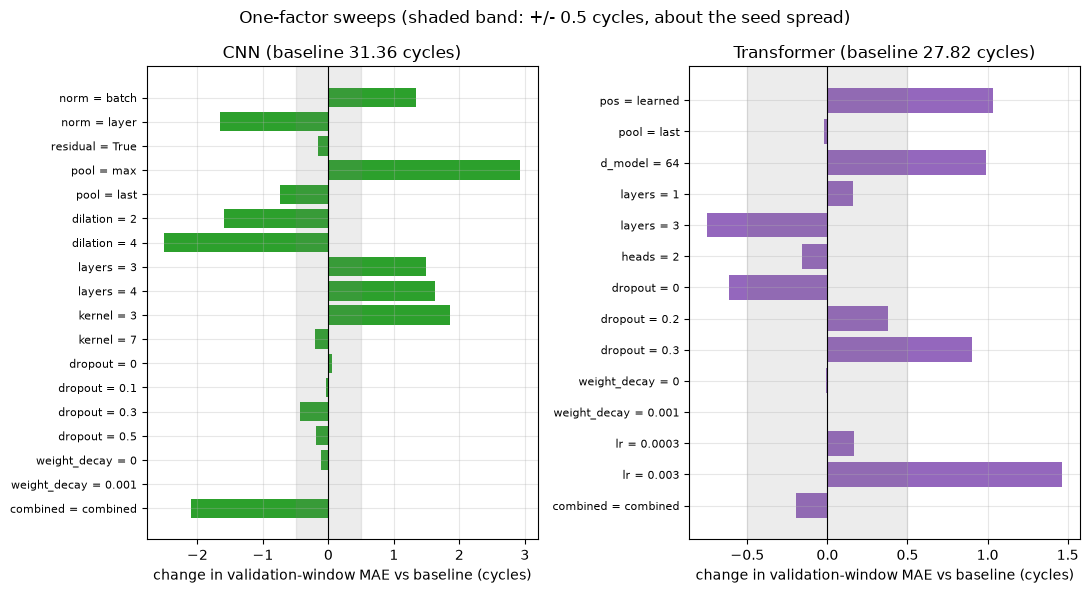

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
for ax, df, title in zip(axes, (cnn_df, tr_df), ("CNN", "Transformer")):
    d = df[df["factor"] != "baseline"].reset_index(drop=True)
    labels = [f"{f} = {v}" for f, v in zip(d["factor"], d["value"])]
    colors = [COLORS["cnn1d"] if title == "CNN" else COLORS["transformer"]] * len(d)
    ax.barh(range(len(d)), d["delta_vs_baseline"], color=colors)
    ax.set_yticks(range(len(d)), labels, fontsize=8)
    ax.invert_yaxis()
    ax.axvline(0, color="k", lw=0.8)
    ax.axvspan(-MIN_GAIN, MIN_GAIN, color="grey", alpha=0.15)
    ax.set_xlabel("change in validation-window MAE vs baseline (cycles)")
    ax.set_title(f"{title} (baseline {df.loc[0, 'val_window_mae']:.2f} cycles)")
fig.suptitle("One-factor sweeps (shaded band: +/- 0.5 cycles, about the seed spread)")
save_fig(fig, "cnn_transformer_sweeps.png")

*Figure: effect of each design factor on validation-window MAE, relative to each model's baseline (seed 42). Differences inside the grey band are within seed noise.*

### Selection (rule written above) and the three seeds

In [10]:
def choose(df):
    # Lowest val_window_mae, ties under TIE go to the smaller model (selection rule steps 2-3).
    pool = df.copy()
    best = pool["val_window_mae"].min()
    near = pool[pool["val_window_mae"] <= best + TIE]
    return near.sort_values(["n_params", "val_window_mae"]).iloc[0]


cnn_choice, tr_choice = choose(cnn_df), choose(tr_df)
for name, c in (("CNN", cnn_choice), ("Transformer", tr_choice)):
    print(f"{name}: chosen = {c['factor']} / {c['value']}  val-window MAE {c['val_window_mae']:.2f}, params {int(c['n_params'])}")


def chosen_config(choice, base_cfg_fn, factors, combined_kw, combined_tr):
    # Rebuild the config of the chosen pool member.
    if choice["factor"] == "baseline":
        return base_cfg_fn({}, {})
    if choice["factor"] == "combined":
        return base_cfg_fn(combined_kw, combined_tr)
    for f, v, k, t in factors:
        if f == choice["factor"] and v == choice["value"]:
            return base_cfg_fn(k, t)


CNN_CHOSEN = chosen_config(cnn_choice, cnn_config, CNN_FACTORS, cnn_kw, cnn_tr)
TR_CHOSEN = chosen_config(tr_choice, tr_config, TR_FACTORS, tr_kw, tr_tr)
print("CNN config:", CNN_CHOSEN["kw"], {k: CNN_CHOSEN[k] for k in ("weight_decay",)})
print("Transformer config:", TR_CHOSEN["kw"], {k: TR_CHOSEN[k] for k in ("weight_decay", "lr")})

CNN: chosen = dilation / 4  val-window MAE 28.86, params 25153
Transformer: chosen = layers / 3  val-window MAE 27.07, params 26209
CNN config: {'channels': 64, 'kernel': 5, 'dropout': 0.2, 'layers': 2, 'dilation': 4, 'norm': 'none', 'residual': False, 'pool': 'avg'} {'weight_decay': 0.0001}
Transformer config: {'d_model': 32, 'heads': 4, 'layers': 3, 'dim_ff': 64, 'dropout': 0.1, 'pos': 'sinusoidal', 'pool': 'mean'} {'weight_decay': 0.0001, 'lr': 0.001}


Train the chosen CNN and Transformer with seeds 42, 43 and 44. `final=True` also scores the 100 fixed validation points and predicts the test points (no test metric is computed).

In [11]:
final_cfgs = [{**CNN_CHOSEN, "seed": s, "final": True} for s in SEEDS] + [{**TR_CHOSEN, "seed": s, "final": True} for s in SEEDS]
final_runs = cx.run_many(final_cfgs, workers=WORKERS)
FINAL = {("cnn1d", s): r for s, r in zip(SEEDS, final_runs[:3])}
FINAL.update({("transformer", s): r for s, r in zip(SEEDS, final_runs[3:])})
for (m, s), r in FINAL.items():
    p = r["points"]
    print(f"{m:11s} seed {s}: params {r['n_params']}, epochs {r['epochs_run']}, best epoch {r['best_epoch']}, "
          f"val-window MAE {r['val_window_mae']:.2f} | 100 points MAE {p['mae']:.2f} RMSE {p['rmse']:.2f}")
# the seed-42 selection run must reproduce the sweep value (determinism check)
for m, choice in (("cnn1d", cnn_choice), ("transformer", tr_choice)):
    assert abs(FINAL[(m, 42)]["val_window_mae"] - choice["val_window_mae"]) < 1e-3, m
print("seed-42 runs reproduce the sweep scores")

cnn1d       seed 42: params 25153, epochs 13, best epoch 5, val-window MAE 28.86 | 100 points MAE 24.32 RMSE 36.70
cnn1d       seed 43: params 25153, epochs 20, best epoch 12, val-window MAE 29.56 | 100 points MAE 24.29 RMSE 36.86
cnn1d       seed 44: params 25153, epochs 19, best epoch 11, val-window MAE 29.96 | 100 points MAE 24.54 RMSE 37.03
transformer seed 42: params 26209, epochs 21, best epoch 13, val-window MAE 27.07 | 100 points MAE 20.59 RMSE 34.79
transformer seed 43: params 26209, epochs 14, best epoch 6, val-window MAE 26.86 | 100 points MAE 22.66 RMSE 36.28
transformer seed 44: params 26209, epochs 14, best epoch 6, val-window MAE 27.62 | 100 points MAE 25.14 RMSE 39.85
seed-42 runs reproduce the sweep scores


### Outputs

Write the prediction files, configs, weights and summary tables. Predictions and weights are those of the seed 42 runs. Standard deviations use `ddof=1` over seeds 42, 43, 44.

In [12]:
NAMES = {"cnn1d": "cnn1d_v1", "transformer": "transformer_v1"}
summary = []
for m in ("cnn1d", "transformer"):
    pts = [FINAL[(m, s)]["points"] for s in SEEDS]
    summary.append({
        "model": NAMES[m], **FINAL[(m, 42)]["points"],
        "mae_std": np.std([p["mae"] for p in pts], ddof=1),
        "rmse_std": np.std([p["rmse"] for p in pts], ddof=1),
        "mae_mean_3seeds": np.mean([p["mae"] for p in pts]),
        "rmse_mean_3seeds": np.mean([p["rmse"] for p in pts]),
    })
summary_df = pd.DataFrame(summary)
summary_df.to_csv(RESULTS / "summary_cnn_transformer.csv", index=False)
print(summary_df.round(2).to_string(index=False))

val_out = data["keys_pt"][["engine_id", "cycle"]].copy()
test_out = data["keys_te"][["engine_id"]].copy()
for m in ("cnn1d", "transformer"):
    val_out[NAMES[m]] = FINAL[(m, 42)]["val_pred"]
    test_out[NAMES[m]] = FINAL[(m, 42)]["test_pred"]
val_out.to_csv(RESULTS / "val_predictions_cnn_transformer.csv", index=False)
test_out.to_csv(RESULTS / "test_predictions_cnn_transformer.csv", index=False)

for m in ("cnn1d", "transformer"):
    res = FINAL[(m, 42)]
    cfg = res["cfg"]
    config = {
        "model": NAMES[m], "kind": m, "kwargs": cfg["kw"], "window": cfg["window"], "seed": cfg["seed"],
        "optimizer": "AdamW", "lr": cfg["lr"], "weight_decay": cfg["weight_decay"], "batch_size": 256,
        "grad_clip": cfg["grad_clip"], "loss": "MSE on RUL/100", "max_epochs": cfg["epochs"],
        "patience": cfg["patience"], "restore_best": cfg["restore_best"],
        "epochs_run": res["epochs_run"], "best_epoch": res["best_epoch"],
        "best_val_window_mae": res["val_window_mae"], "n_params": res["n_params"],
        "val_points": res["points"], "seeds_reported": list(SEEDS),
    }
    if m == "cnn1d":
        config["receptive_field"] = CNN1DRegressor(**cfg["kw"]).receptive_field
    (RESULTS / f"config_{m}.json").write_text(json.dumps(config, indent=2))
    model = build_model(m, **cfg["kw"])
    model.load_state_dict(res["state_dict"])
    train.save_model(model, MODEL_DIR / f"{NAMES[m]}.pt")

reg_df = pd.concat([cnn_df, tr_df], ignore_index=True)[
    ["model", "factor", "value", "val_window_mae", "train_loss_final", "train_mae", "best_epoch",
     "epochs_run", "n_params", "delta_vs_baseline"]]
reg_df.to_csv(RESULTS / "cnn_transformer_regularization.csv", index=False)
print("rows in cnn_transformer_regularization.csv:", len(reg_df))

         model   mae  rmse  early_mae  late_mae  mae_std  rmse_std  mae_mean_3seeds  rmse_mean_3seeds
      cnn1d_v1 24.32 36.70      41.33     19.53     0.14      0.17            24.38             36.86
transformer_v1 20.59 34.79      41.10     14.80     2.28      2.60            22.80             36.97
rows in cnn_transformer_regularization.csv: 34


Check that every output file has the agreed schema (100 rows, column order, no NaN, validation order equals the fixed points, test engines 1 to 100) and that each saved model reloads through `train.load_model` and reproduces its predictions.

In [13]:
for name, df, cols in [
    ("val_predictions_cnn_transformer.csv", val_out, ["engine_id", "cycle", "cnn1d_v1", "transformer_v1"]),
    ("test_predictions_cnn_transformer.csv", test_out, ["engine_id", "cnn1d_v1", "transformer_v1"]),
]:
    saved = pd.read_csv(RESULTS / name)
    assert list(saved.columns) == cols and len(saved) == 100 and not saved.isna().any().any(), name
    assert (saved.drop(columns=["engine_id", "cycle"], errors="ignore").to_numpy() >= 0).all(), name
assert (pd.read_csv(RESULTS / "val_predictions_cnn_transformer.csv")[["engine_id", "cycle"]].to_numpy()
        == points[["engine_id", "cycle"]].to_numpy()).all()
assert list(pd.read_csv(RESULTS / "test_predictions_cnn_transformer.csv")["engine_id"]) == list(range(1, 101))
for m in ("cnn1d", "transformer"):
    cfg = json.loads((RESULTS / f"config_{m}.json").read_text())
    reloaded = train.load_model(m, MODEL_DIR / f"{NAMES[m]}.pt", **cfg["kwargs"])
    assert np.allclose(train.predict(reloaded, data["X_pt"]), val_out[NAMES[m]].to_numpy(), atol=1e-3), m
    assert abs(train.evaluate_points(reloaded, data["X_pt"], data["y_pt"])["mae"] - cfg["val_points"]["mae"]) < 1e-3, m
print("all output files pass the schema and reload checks")

all output files pass the schema and reload checks


### Learning curves

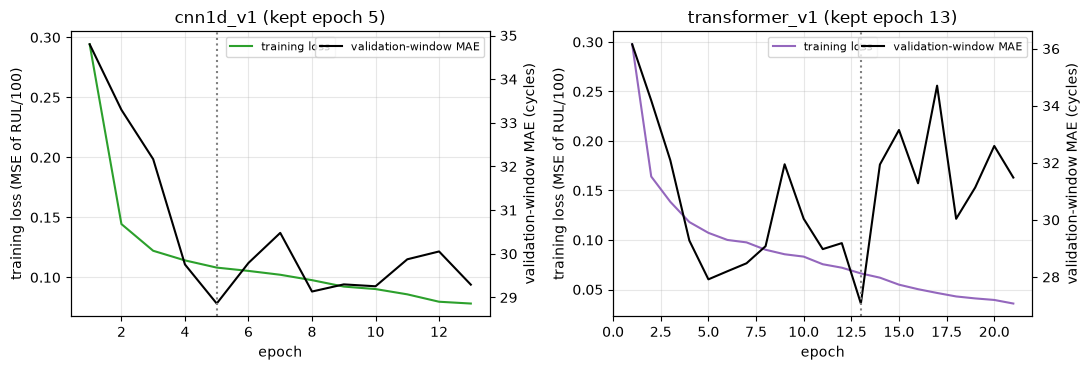

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, m in zip(axes, ("cnn1d", "transformer")):
    h = FINAL[(m, 42)]["history"]
    ep = np.arange(1, len(h["val_mae"]) + 1)
    ax.plot(ep, h["train_loss"], color=COLORS[m], label="training loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("training loss (MSE of RUL/100)")
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(ep, h["val_mae"], color="k", label="validation-window MAE")
    ax2.axvline(h["best_epoch"][0], color="grey", ls=":")
    ax2.set_ylabel("validation-window MAE (cycles)")
    ax.set_title(f"{NAMES[m]} (kept epoch {h['best_epoch'][0]})")
    ax.legend(loc="upper center", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
save_fig(fig, "cnn_transformer_learning_curves.png")

*Figure: training loss (dropout active) and validation-window MAE per epoch for the seed 42 runs. The dotted line marks the epoch whose weights were kept.*

### Comparison with the recurrent models and Phase 1 (read from files)

The numbers of the other members are read from their result files, never typed by hand. Parameter counts and timing for all four deep models are measured below under the same conditions.

In [15]:
rnn_summary = pd.read_csv(RESULTS / "summary_rnn.csv").set_index("model")
phase1 = pd.read_csv(ROOT / "results" / "phase1" / "final_results.csv")
phase1 = phase1[phase1["set"] == "validation"].set_index("model")

rows = []
for name in ("ols_v1", "elastic_net_v2", "random_forest", "gradient_boosting"):
    rows.append({"model": name, "family": "Phase 1", "mae": phase1.loc[name, "mae"], "mae_std": np.nan,
                 "rmse": phase1.loc[name, "rmse"], "rmse_std": np.nan})
for name in ("lstm_v1", "gru_v1"):
    r = rnn_summary.loc[name]
    rows.append({"model": name, "family": "Phase 2 recurrent", "mae": r["mae_mean_3seeds"], "mae_std": r["mae_std"],
                 "rmse": r["rmse_mean_3seeds"], "rmse_std": r["rmse_std"]})
for _, r in summary_df.iterrows():
    rows.append({"model": r["model"], "family": "Phase 2 CNN / Transformer", "mae": r["mae_mean_3seeds"],
                 "mae_std": r["mae_std"], "rmse": r["rmse_mean_3seeds"], "rmse_std": r["rmse_std"]})
compare = pd.DataFrame(rows)
print("Validation, 100 fixed points; Phase 2 rows are the mean and std over seeds 42-44:")
print(compare.round(2).to_string(index=False))

Validation, 100 fixed points; Phase 2 rows are the mean and std over seeds 42-44:
            model                    family   mae  mae_std  rmse  rmse_std
           ols_v1                   Phase 1 32.86      NaN 42.92       NaN
   elastic_net_v2                   Phase 1 31.66      NaN 41.77       NaN
    random_forest                   Phase 1 25.03      NaN 40.17       NaN
gradient_boosting                   Phase 1 26.12      NaN 40.17       NaN
          lstm_v1         Phase 2 recurrent 20.14     1.46 33.18      2.46
           gru_v1         Phase 2 recurrent 22.98     0.49 36.61      0.90
         cnn1d_v1 Phase 2 CNN / Transformer 24.38     0.14 36.86      0.17
   transformer_v1 Phase 2 CNN / Transformer 22.80     2.28 36.97      2.60


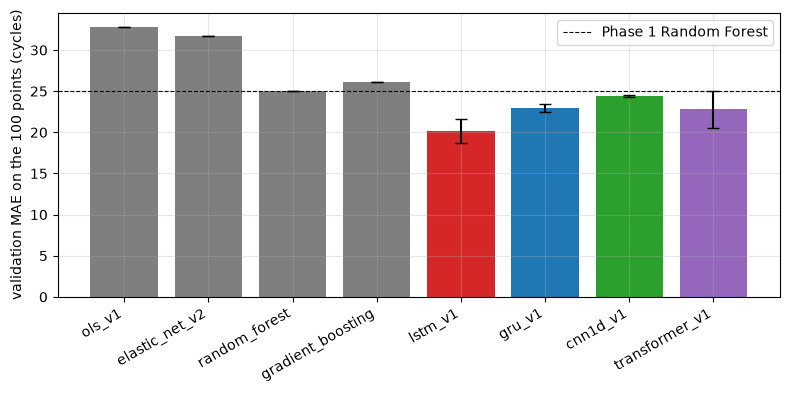

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#7f7f7f"] * 4 + [COLORS["lstm"], COLORS["gru"], COLORS["cnn1d"], COLORS["transformer"]]
ax.bar(range(len(compare)), compare["mae"], yerr=compare["mae_std"].fillna(0), color=colors, capsize=4)
ax.set_xticks(range(len(compare)), compare["model"], rotation=30, ha="right")
ax.set_ylabel("validation MAE on the 100 points (cycles)")
ax.axhline(phase1.loc["random_forest", "mae"], color="k", ls="--", lw=0.8, label="Phase 1 Random Forest")
ax.legend()
save_fig(fig, "cnn_transformer_dl_comparison.png")

*Figure: validation MAE on the 100 fixed points. Grey bars are Phase 1 models (one run). Coloured bars are the mean over seeds 42, 43, 44 with the standard deviation as error bar.*

### Parameters and training time of all four deep models

Measured on one CPU thread, three epochs each, with the chosen configuration of every model. LSTM and GRU configurations are read from `config_lstm.json` and `config_gru.json`.

In [17]:
rnn_cfgs = {k: json.loads((RESULTS / f"config_{k}.json").read_text()) for k in ("lstm", "gru")}
cost_specs = {
    "lstm": ("lstm", {"hidden": rnn_cfgs["lstm"]["hidden"], "layers": rnn_cfgs["lstm"]["layers"], "dropout": rnn_cfgs["lstm"]["dropout"]}),
    "gru": ("gru", {"hidden": rnn_cfgs["gru"]["hidden"], "layers": rnn_cfgs["gru"]["layers"], "dropout": rnn_cfgs["gru"]["dropout"]}),
    "cnn1d": ("cnn1d", CNN_CHOSEN["kw"]),
    "transformer": ("transformer", TR_CHOSEN["kw"]),
}
import time
cost_rows = []
for name, (kind, kw) in cost_specs.items():
    train.set_seed(42)
    model = build_model(kind, **kw)
    start = time.perf_counter()
    train.fit(model, data["X_tr"], data["y_tr"], data["X_va"], data["y_va"], epochs=3, patience=99,
              restore_best=False, device=torch.device("cpu"))
    cost_rows.append({"model": name, "parameters": sum(p.numel() for p in model.parameters()),
                      "seconds_per_epoch": (time.perf_counter() - start) / 3, "window": DEFAULT_WINDOW})
cost_df = pd.DataFrame(cost_rows)
cost_df.to_csv(RESULTS / "model_cost.csv", index=False)
print(cost_df.round(2).to_string(index=False))

# attention cost, quadratic in the window: entries of one head's attention matrix and multiply-adds for QK^T and AV
d_model = TR_CHOSEN["kw"]["d_model"]
for w in (30, 50):
    print(f"window {w}: {w * w} attention entries per head and layer, "
          f"{2 * w * w * d_model} multiply-adds for QK^T and AV per sample and layer (d_model {d_model})")

      model  parameters  seconds_per_epoch  window
       lstm       20545               0.67      30
        gru       40385               1.15      30
      cnn1d       25153               2.10      30
transformer       26209               3.78      30
window 30: 900 attention entries per head and layer, 57600 multiply-adds for QK^T and AV per sample and layer (d_model 32)
window 50: 2500 attention entries per head and layer, 160000 multiply-adds for QK^T and AV per sample and layer (d_model 32)


### Predicted against true RUL and error by RUL band

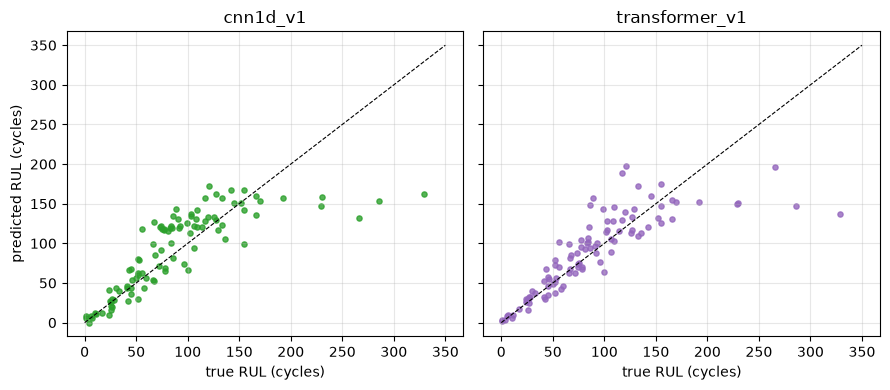

In [18]:
y_pt = data["y_pt"]
rnn_val = pd.read_csv(RESULTS / "val_predictions_rnn.csv")
assert (rnn_val[["engine_id", "cycle"]].to_numpy() == val_out[["engine_id", "cycle"]].to_numpy()).all()
preds = {"lstm_v1": rnn_val["lstm_v1"].to_numpy(), "gru_v1": rnn_val["gru_v1"].to_numpy(),
         "cnn1d_v1": val_out["cnn1d_v1"].to_numpy(), "transformer_v1": val_out["transformer_v1"].to_numpy()}

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, m in zip(axes, ("cnn1d_v1", "transformer_v1")):
    key = m.replace("_v1", "")
    ax.scatter(y_pt, preds[m], s=14, color=COLORS[key], alpha=0.8)
    ax.plot([0, 350], [0, 350], "k--", lw=0.8)
    ax.set_title(m); ax.set_xlabel("true RUL (cycles)")
axes[0].set_ylabel("predicted RUL (cycles)")
save_fig(fig, "cnn_transformer_pred_vs_true.png")

*Figure: predicted against true RUL on the 100 validation points. The dashed line is a perfect prediction.*

model    cnn1d_v1  gru_v1  lstm_v1  transformer_v1
band                                              
0-50          1.8     2.7      3.4             2.3
50-100       20.6    16.4      8.0            11.7
100-150      12.6    17.6      6.7             9.3
150-200     -18.0   -21.2    -18.3           -17.9
200+       -117.5  -115.8   -124.7          -111.9
points per band: {'0-50': 27, '50-100': 37, '100-150': 23, '150-200': 8, '200+': 5}


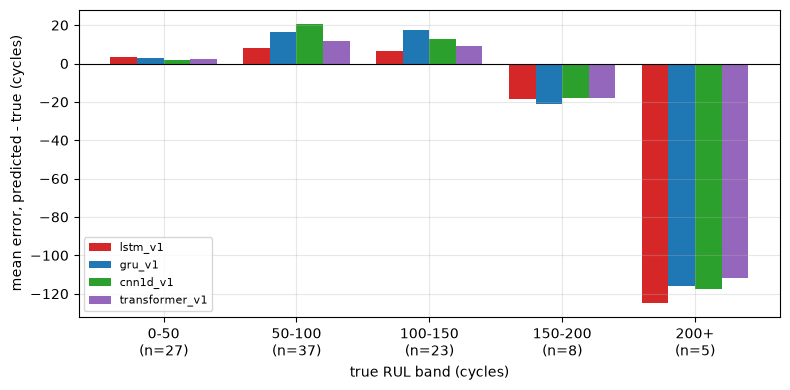

In [19]:
BANDS = [(0, 50), (50, 100), (100, 150), (150, 200), (200, 10_000)]
band_names = ["0-50", "50-100", "100-150", "150-200", "200+"]
band_rows = []
for m, p in preds.items():
    for (lo, hi), name in zip(BANDS, band_names):
        mask = (y_pt >= lo) & (y_pt < hi) if hi < 10_000 else (y_pt >= lo)
        err = p[mask] - y_pt[mask]
        band_rows.append({"model": m, "band": name, "n": int(mask.sum()),
                          "mean_error": err.mean() if mask.any() else np.nan,
                          "mae": np.abs(err).mean() if mask.any() else np.nan})
band_df = pd.DataFrame(band_rows)
print(band_df.pivot(index="band", columns="model", values="mean_error").loc[band_names].round(1).to_string())
print("points per band:", dict(band_df[band_df["model"] == "cnn1d_v1"][["band", "n"]].values))

fig, ax = plt.subplots(figsize=(8, 4))
width = 0.2
for i, m in enumerate(preds):
    sub = band_df[band_df["model"] == m].set_index("band").loc[band_names]
    ax.bar(np.arange(5) + (i - 1.5) * width, sub["mean_error"], width, label=m, color=COLORS[m.replace("_v1", "")])
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(5), [f"{n}\n(n={int(band_df[(band_df['model']=='cnn1d_v1') & (band_df['band']==n)]['n'].iloc[0])})" for n in band_names])
ax.set_xlabel("true RUL band (cycles)"); ax.set_ylabel("mean error, predicted - true (cycles)")
ax.legend(fontsize=8)
save_fig(fig, "cnn_transformer_error_by_band.png")

*Figure: mean signed error by true-RUL band for the four deep models (negative = underprediction). The band 200+ has only 5 points.*

### Attention map of the Transformer

First-layer attention (averaged over heads) for two validation windows: one close to failure and one early in life. Rows are the query cycle, columns the cycle attended to; the right-most column is the current cycle. This shows where the first layer looks, not a full explanation of the prediction.

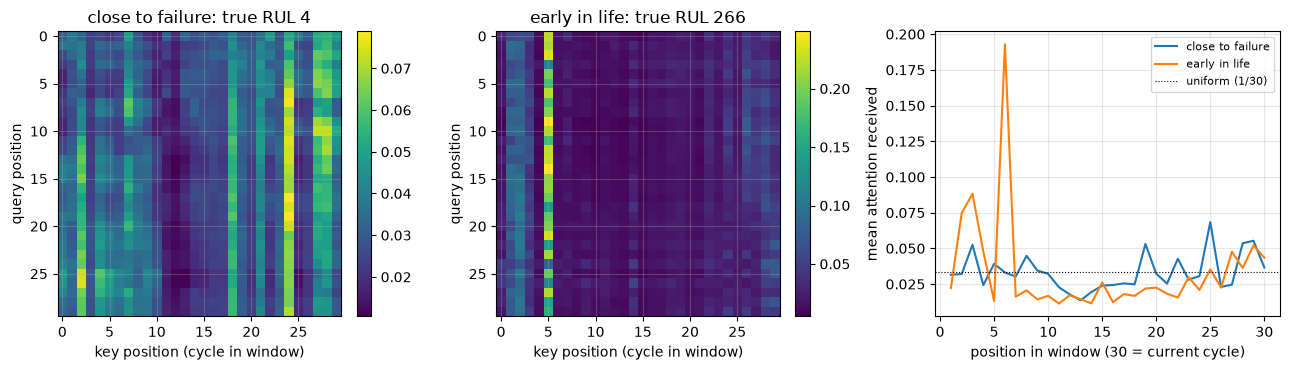

close to failure: share of attention on the last 5 cycles 0.19 (uniform would be 0.17), on the first 5 cycles 0.18
early in life: share of attention on the last 5 cycles 0.20 (uniform would be 0.17), on the first 5 cycles 0.25


In [20]:
tr_model = train.load_model("transformer", MODEL_DIR / "transformer_v1.pt", **TR_CHOSEN["kw"]).eval()
order = np.argsort(y_pt)
picks = {"close to failure": order[2], "early in life": order[-3]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})
received = {}
for ax, (name, idx) in zip(axes, picks.items()):
    with torch.no_grad():
        w = tr_model.attention_weights(torch.from_numpy(data["X_pt"][idx:idx + 1]))[0].numpy()
    im = ax.imshow(w, cmap="viridis", aspect="auto")
    ax.set_title(f"{name}: true RUL {y_pt[idx]:.0f}"); ax.set_xlabel("key position (cycle in window)"); ax.set_ylabel("query position")
    received[name] = w.mean(axis=0)
    fig.colorbar(im, ax=ax, fraction=0.046)
for name, r in received.items():
    axes[2].plot(range(1, 31), r, label=name)
axes[2].axhline(1 / 30, color="k", ls=":", lw=0.8, label="uniform (1/30)")
axes[2].set_xlabel("position in window (30 = current cycle)"); axes[2].set_ylabel("mean attention received"); axes[2].legend(fontsize=8)
save_fig(fig, "transformer_attention_map.png")
for name, r in received.items():
    print(f"{name}: share of attention on the last 5 cycles {r[-5:].sum():.2f} (uniform would be {5 / 30:.2f}), on the first 5 cycles {r[:5].sum():.2f}")

*Figure: first-layer self-attention for one window close to failure and one early in life (left, middle) and the mean attention each position receives (right).*

### Which model gives the best embedding for a hybrid model?

Kapish's hybrid uses an out-of-fold scalar prediction rather than a raw embedding, but `encode` is still the natural summary of a window, so check how informative it is. A ridge regression is fitted from each model's `encode` vector to RUL on the training windows and scored on the validation-engine windows. The encoders were trained on the training engines, so the probe is evaluated on engines the encoder never trained on.

In [21]:
def embed(model, X, batch=2048):
    model.eval()
    with torch.no_grad():
        return np.concatenate([model.encode(torch.from_numpy(X[i:i + batch])).numpy() for i in range(0, len(X), batch)])


probe_rows = []
rnn_models = {k: train.load_model(k, MODEL_DIR / f"{k}_v1.pt", hidden=rnn_cfgs[k]["hidden"], layers=rnn_cfgs[k]["layers"],
                                  dropout=rnn_cfgs[k]["dropout"]) for k in ("lstm", "gru")}
all_models = {**rnn_models,
              "cnn1d": train.load_model("cnn1d", MODEL_DIR / "cnn1d_v1.pt", **CNN_CHOSEN["kw"]),
              "transformer": tr_model}
for name, mdl in all_models.items():
    Z_tr, Z_va = embed(mdl, data["X_tr"]), embed(mdl, data["X_va"])
    probe = Ridge(alpha=1.0).fit(Z_tr, data["y_tr"])
    head_mae = float(np.mean(np.abs(train.predict(mdl, data["X_va"]) - data["y_va"])))
    probe_mae = float(np.mean(np.abs(np.clip(probe.predict(Z_va), 0, None) - data["y_va"])))
    probe_rows.append({"model": name, "embedding_dim": Z_tr.shape[1], "own_head_val_window_mae": head_mae,
                       "ridge_probe_val_window_mae": probe_mae})
probe_df = pd.DataFrame(probe_rows)
probe_df.to_csv(RESULTS / "embedding_probe.csv", index=False)
print(probe_df.round(2).to_string(index=False))

      model  embedding_dim  own_head_val_window_mae  ridge_probe_val_window_mae
       lstm             64                    26.38                       26.54
        gru             64                    26.78                       26.82
      cnn1d             64                    28.86                       29.14
transformer             32                    27.07                       29.46


## Conclusion

All numbers below are printed by the cells above and stored in `results/phase2/`. Validation MAE is on the 100 fixed points (cycles), as mean and standard deviation over seeds 42, 43, 44.

**What was chosen.** The selection rule picked the CNN with dilation 4 (validation-window MAE 28.86, baseline 31.36; receptive field 33 cycles, the whole 30-cycle window) and the 3-layer Transformer (27.07, baseline 27.82). Both have about 25,000 to 26,000 parameters.

**Result.** CNN: MAE 24.38 +/- 0.14, RMSE 36.86 +/- 0.17. Transformer: MAE 22.80 +/- 2.28, RMSE 36.97 +/- 2.60. For reference (read from files): LSTM 20.14 +/- 1.46, GRU 22.98 +/- 0.49, Phase 1 Random Forest 25.03. The ranking by the selection score (all windows of the 20 validation engines) is LSTM 26.38, GRU 26.78, Transformer 27.07, CNN 28.86, and the ranking by 100-point MAE is the same except that the Transformer and GRU are tied. The saved seed-42 models score 24.32 (CNN) and 20.59 (Transformer); the Transformer's seed 42 run is its best of three, so the mean is the fair number.

**Is the gap larger than the seed spread?** Only partly. The Transformer is better than Random Forest by 2.2 cycles, which is about one seed standard deviation (2.28) and therefore not clearly better; its seed spread is large (20.59, 22.66, 25.14). The CNN is 0.65 cycles better than Random Forest with a tiny seed spread, but Random Forest is a single run and the 100 points come from only 20 engines, so this is not evidence of a real difference. Neither model beats the LSTM (20.14), and the Transformer and GRU are tied. This is an honest negative result for the "non-recurrent models are better" idea on 30-cycle windows.

**What mattered in the design.**
- *CNN:* the receptive field. Dilation 2 and 4 (field 17 and 33 cycles) improved on the baseline field of 9 cycles by 1.6 and 2.5 cycles. Deeper stacks (3 and 4 layers) got worse (+1.5, +1.6) because they overfit (training MAE 11.9 and 10.7 against 22.0), a smaller kernel hurt (+1.9), and max pooling hurt most (+2.9). Layer normalisation helped (-1.6) but reached a training MAE of 6.6, so it fits the training engines much more closely; batch normalisation hurt (+1.3). Residual connections, dropout and weight decay were within seed noise. The combined run (layer norm, last-step pooling, dilation 4) scored 29.27, worse than dilation 4 alone (28.86): the improvements did not add up.
- *Transformer:* almost nothing beyond noise. A third layer (-0.75) and no dropout (-0.61) were the only single changes above the 0.5 cycle band; learned positions (+1.0), a larger `d_model` (+1.0) and a larger learning rate (+1.5) were worse; weight decay had no effect. A 795,393-parameter model (30 times larger) reached a training MAE of 6.5 but the same validation-window MAE (27.76 against 27.82), which is the overfitting that 80 engines allow.

**Cost.** Measured on one CPU thread: LSTM 20,545 parameters and 0.67 s per epoch, GRU 40,385 and 1.15 s, CNN 25,153 and 2.10 s, Transformer 26,209 and 3.78 s. The recurrent models are as accurate or better and cheaper. The attention map has 900 entries per head and layer for a window of 30 and 2,500 for 50.

**High-RUL underprediction is not fixed.** For true RUL above 200 (5 points) the mean error is -117.5 (CNN) and -111.9 (Transformer), against -124.7 (LSTM) and -115.8 (GRU). All four models underpredict by more than 110 cycles, so the cause is more likely the information in a 30-cycle window of an engine that is still healthy than the architecture.

**Attention.** First-layer attention is not concentrated on recent cycles: the share on the last 5 cycles is 0.19 and 0.20 against 0.17 for uniform attention. For the early-life window (engine 69, cycle 96, true RUL 266) one position (cycle 6 of the window) receives a mean attention of about 0.19, and for the window close to failure (engine 90, cycle 150, true RUL 4) attention is spread out. This describes where the first layer looks; it is not a full explanation of the prediction.

**Recommendation for the hybrid model.** The ridge probe on `encode` vectors (validation-engine windows) gives 26.54 (LSTM), 26.82 (GRU), 29.14 (CNN) and 29.46 (Transformer), against each model's own head at 26.38, 26.78, 28.86 and 27.07. The CNN embedding keeps almost all information linearly (0.28 cycles lost), while the Transformer's pooled embedding loses 2.4 cycles, so its head does work a linear probe cannot. For a stacked scalar `d`, the best choice by the selection score is the LSTM, then the Transformer. If an embedding is wanted, use the CNN or the LSTM. Whatever is used must be produced out of fold (see the leakage note in the hybrid prompt), because these encoders were trained on the training engines.

**Limits.** 100 points from 20 engines; validation scores are slightly optimistic because early stopping and selection used the 20 validation engines; single-factor differences below about 1 cycle are within seed noise; the Transformer's seed spread (2.28) is large, so three seeds give only a rough mean. No test metric was computed.

### Handoff

Files produced by this notebook are listed in `docs/handoff/03_abhishek.md`.